# 06 · Walk-forward backtesting

**Goal of this notebook:** commits 6–8 judged the models on one validation season (2025-26) and
a partial test season (2026-27). One season is a small sample, so this notebook asks a broader
question: **how would the same models have done, season after season, if we had used them in the
past?**

## Method: expanding-window walk-forward evaluation

Each historical season from 2018-19 to 2024-25 is
predicted by models that only saw the seasons before it:

| Evaluation season | Final training seasons | Past-only tuning (feature set + hyperparameters) |
|---|---|---|
| 2018-19 | 1993-94 to 2017-18 | train to 2016-17, validate on 2017-18 |
| 2019-20 | 1993-94 to 2018-19 | train to 2017-18, validate on 2018-19 |
| 2020-21 | 1993-94 to 2019-20 | train to 2018-19, validate on 2019-20 |
| 2021-22 | 1993-94 to 2020-21 | train to 2019-20, validate on 2020-21 |
| 2022-23 | 1993-94 to 2021-22 | train to 2020-21, validate on 2021-22 |
| 2023-24 | 1993-94 to 2022-23 | train to 2021-22, validate on 2022-23 |
| 2024-25 | 1993-94 to 2023-24 | train to 2022-23, validate on 2023-24 |

For each evaluation season S:
1. **Hide the future.** Every season after S is removed before anything else happens.
2. **Tune on the past.** Every candidate (feature set × the model's grid) is fitted on seasons up
   to S-2 and scored on S-1. The lowest log loss wins.
3. **Refit and predict.** The winner is refitted on all seasons up to S-1 and predicts every
   match of S.

Season S's results are only used to score the predictions: never for fitting, imputation, feature
selection or tuning. The window **expands**: each fold trains on every earlier season.

**Why past-only tuning instead of the commit-7 settings?** The settings in `src/models.py` used
by commits 7–9 (e.g. Random Forest depth 12) were chosen on **2025-26**. Using them to predict
2018-19 would let a later season configure an earlier forecast, and the backtest scores would
look better than they should. So each fold picks its own settings from the same predefined
grids, using only earlier seasons. One honest caveat remains: the *grid ranges* were fixed in
commit 7, partly after looking at 2025-26, so the backtest is not perfectly blind. The grids are
broad (9–12 candidates each, two feature sets), so this second-order effect should be small.

**What is not touched:**
- The 2026-27 holdout is never used; `src/backtest.py` refuses it.
- 2025-26 is not a backtest season either, so the commit-7 validation results and the commit-8
  analysis stay exactly as they were.

Benchmarks:
- **Baseline:** the outcome frequencies of each fold's training seasons.
- **Bookmaker:** Bet365 odds with the margin removed. It is scored only on fixtures with complete
  odds, and so are all the other forecasts, so everything is compared on identical matches.

The code is in `src/backtest.py`; `python -m src.backtest` runs the same backtest from the
command line.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator, PercentFormatter

from src.backtest import (
    BACKTEST_SEASONS, BASELINE, FORECASTS, METRICS, MODELS, coverage_table, pooled_bootstrap, pooled_metrics,
    run_backtest, save_backtest, season_metrics, season_ranks, seasonal_bootstrap, summary_table,
)
from src.bookmaker import BOOKMAKER_LABEL
from src.config import FIGURES_DIR, MODELS_DIR
from src.feature_engineering import load_features
from src.preprocessing import load_matches
from src.train import season_name

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

features = load_features()
matches = load_matches()

start = time.time()
backtest = run_backtest(features, matches)  # about 6 minutes: 7 seasons x 3 models, each tuned on its own past
paths = save_backtest(backtest)
print(f"Backtest finished in {(time.time() - start) / 60:.1f} minutes")
for name, path in paths.items():
    print(f"saved {name}: {path.relative_to(path.parents[2])}")

predictions = backtest.predictions
SEASON_LABELS = {s: season_name(s) for s in BACKTEST_SEASONS}

Backtest finished in 7.0 minutes
saved predictions: outputs\backtest\predictions.csv
saved folds: outputs\backtest\folds.csv


In [2]:
# --- Chart style (same as notebooks 01-05) -------------------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE_LINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a3a29b"
COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA,
          BOOKMAKER_LABEL: YELLOW, BASELINE: GRAY}
SHORT = {"Logistic Regression": "LR", "Random Forest": "RF", "XGBoost": "XGB",
         BOOKMAKER_LABEL: "Bookmaker", BASELINE: "Baseline"}


def style_axes(ax, grid="y"):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE_LINE)
    ax.tick_params(colors=MUTED, labelsize=8, length=0)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)


def set_title(ax, title, subtitle=None, size=12):
    ax.set_title(title, loc="left", fontsize=size, color=INK, pad=26 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, fontsize=9, color=INK_2, va="bottom")


def save_figure(fig, name):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / name, dpi=150, facecolor=SURFACE, bbox_inches="tight")

## 1. Settings chosen by each fold

Each cell shows the feature set and hyperparameters that the fold selected using only earlier
seasons.

In [3]:
folds = backtest.folds.copy()


def describe(row):
    params = json.loads(row["params"])
    short = {"C": "C", "max_depth": "depth", "min_samples_leaf": "leaf", "n_estimators": "trees"}
    return row["feature_set"] + ": " + ", ".join(f"{short.get(k, k)} {v}" for k, v in params.items())


folds["selected"] = folds.apply(describe, axis=1)
settings = folds.pivot(index="season", columns="model", values="selected")[MODELS]
settings.index = settings.index.map(SEASON_LABELS)
display(settings)
training = folds.drop_duplicates("season").set_index("season")[["first_train_season", "last_train_season",
                                                                 "train_matches"]]
training.index = training.index.map(SEASON_LABELS)
training.style.format({"train_matches": "{:,}"})

model,Logistic Regression,Random Forest,XGBoost
season,,,
2018-19,all: C 0.01,"compact: depth None, leaf 20","all: depth 2, trees 500"
2019-20,all: C 0.0003,"all: depth 12, leaf 10","all: depth 4, trees 100"
2020-21,compact: C 0.1,"compact: depth None, leaf 50","compact: depth 3, trees 250"
2021-22,all: C 1.0,"compact: depth None, leaf 10","all: depth 4, trees 250"
2022-23,compact: C 0.0003,"compact: depth None, leaf 10","all: depth 4, trees 250"
2023-24,compact: C 1.0,"all: depth None, leaf 10","all: depth 2, trees 250"
2024-25,all: C 0.001,"all: depth 12, leaf 10","compact: depth 2, trees 250"


,first_train_season,last_train_season,train_matches
season,,,
2018-19,1993,2017,"8,686"
2019-20,1993,2018,"9,066"
2020-21,1993,2019,"9,446"
2021-22,1993,2020,"9,826"
2022-23,1993,2021,"10,206"
2023-24,1993,2022,"10,586"
2024-25,1993,2023,"10,966"


**Interpretation**

- **The selected settings change a lot from fold to fold.**
  - Logistic Regression's `C` ranges from 0.0003 to 1.0.
  - The feature set flips between `all` and `compact`.
  - XGBoost uses trees of depth 2, 3 and 4.
- That does not mean the models are unstable. As in commit 7, the tuning landscape is very flat:
  many candidates score within a few thousandths of log loss of each other on one validation
  season, so small differences between seasons decide which one wins.
- Random Forest settles on unlimited depth (`None`) with small leaves in most folds, and on depth
  12 / leaf 10 in two folds.
- Every training window starts in 1993-94 and grows by one season per fold, from 8,686 to 10,966
  training matches.

## 2. Sample sizes and bookmaker coverage

In [4]:
coverage = coverage_table(predictions)
coverage.index = coverage.index.map(SEASON_LABELS)
total = coverage[["fixtures", "with_odds"]].sum()
print(f"{int(total['with_odds']):,} of {int(total['fixtures']):,} fixtures have complete Bet365 odds "
      f"({total['with_odds'] / total['fixtures']:.2%}); every forecast is scored on exactly these fixtures.")
coverage.style.format({"coverage": "{:.1%}"})

2,657 of 2,660 fixtures have complete Bet365 odds (99.89%); every forecast is scored on exactly these fixtures.


,fixtures,with_odds,coverage
season,,,
2018-19,380,380,100.0%
2019-20,380,380,100.0%
2020-21,380,378,99.5%
2021-22,380,379,99.7%
2022-23,380,380,100.0%
2023-24,380,380,100.0%
2024-25,380,380,100.0%


## 3. Season by season

In [5]:
seasonal = season_metrics(predictions)
fmt = {"accuracy": "{:.1%}", "macro_f1": "{:.3f}", "log_loss": "{:.3f}", "brier": "{:.3f}"}
for metric, label in (("log_loss", "Log loss (lower is better)"), ("brier", "Brier score (lower is better)"),
                      ("accuracy", "Accuracy (higher is better)"), ("macro_f1", "Macro F1 (higher is better)")):
    wide = seasonal[metric].unstack("forecast")[FORECASTS]
    wide.index = wide.index.map(SEASON_LABELS)
    best = wide.idxmin(axis=1) if metric in ("log_loss", "brier") else wide.idxmax(axis=1)
    styled = wide.style.format(fmt[metric]).set_caption(label)
    styled = styled.highlight_min(axis=1, color="#d9f2e6") if metric in ("log_loss", "brier") else \
        styled.highlight_max(axis=1, color="#d9f2e6")
    display(styled)

forecast,Logistic Regression,Random Forest,XGBoost,Bookmaker (Bet365),Baseline
season,,,,,
2018-19,0.985,0.984,0.984,0.945,1.078
2019-20,0.992,0.999,0.997,0.963,1.096
2020-21,0.949,0.947,0.940,0.934,1.096
2021-22,1.005,0.988,0.987,0.976,1.106
2022-23,0.981,0.999,0.991,0.983,1.085
2023-24,0.988,0.977,0.988,0.967,1.086
2024-25,0.984,0.986,0.978,0.955,1.098


forecast,Logistic Regression,Random Forest,XGBoost,Bookmaker (Bet365),Baseline
season,,,,,
2018-19,0.583,0.584,0.583,0.559,0.652
2019-20,0.587,0.593,0.592,0.569,0.664
2020-21,0.563,0.561,0.558,0.550,0.665
2021-22,0.597,0.588,0.588,0.580,0.672
2022-23,0.587,0.597,0.590,0.586,0.657
2023-24,0.590,0.583,0.591,0.576,0.658
2024-25,0.589,0.590,0.587,0.568,0.666


forecast,Logistic Regression,Random Forest,XGBoost,Bookmaker (Bet365),Baseline
season,,,,,
2018-19,52.9%,53.2%,55.3%,55.0%,43.7%
2019-20,53.4%,53.4%,54.2%,56.3%,41.6%
2020-21,55.3%,55.8%,55.3%,56.9%,40.7%
2021-22,53.3%,52.0%,54.1%,52.5%,38.8%
2022-23,54.2%,53.4%,53.7%,52.4%,42.4%
2023-24,53.2%,52.9%,52.9%,55.0%,41.8%
2024-25,52.4%,52.9%,52.6%,52.9%,39.7%


forecast,Logistic Regression,Random Forest,XGBoost,Bookmaker (Bet365),Baseline
season,,,,,
2018-19,0.425,0.416,0.448,0.419,0.203
2019-20,0.390,0.396,0.410,0.418,0.196
2020-21,0.425,0.422,0.427,0.431,0.193
2021-22,0.429,0.408,0.440,0.400,0.186
2022-23,0.410,0.417,0.443,0.395,0.198
2023-24,0.429,0.417,0.422,0.430,0.197
2024-25,0.438,0.427,0.414,0.407,0.190


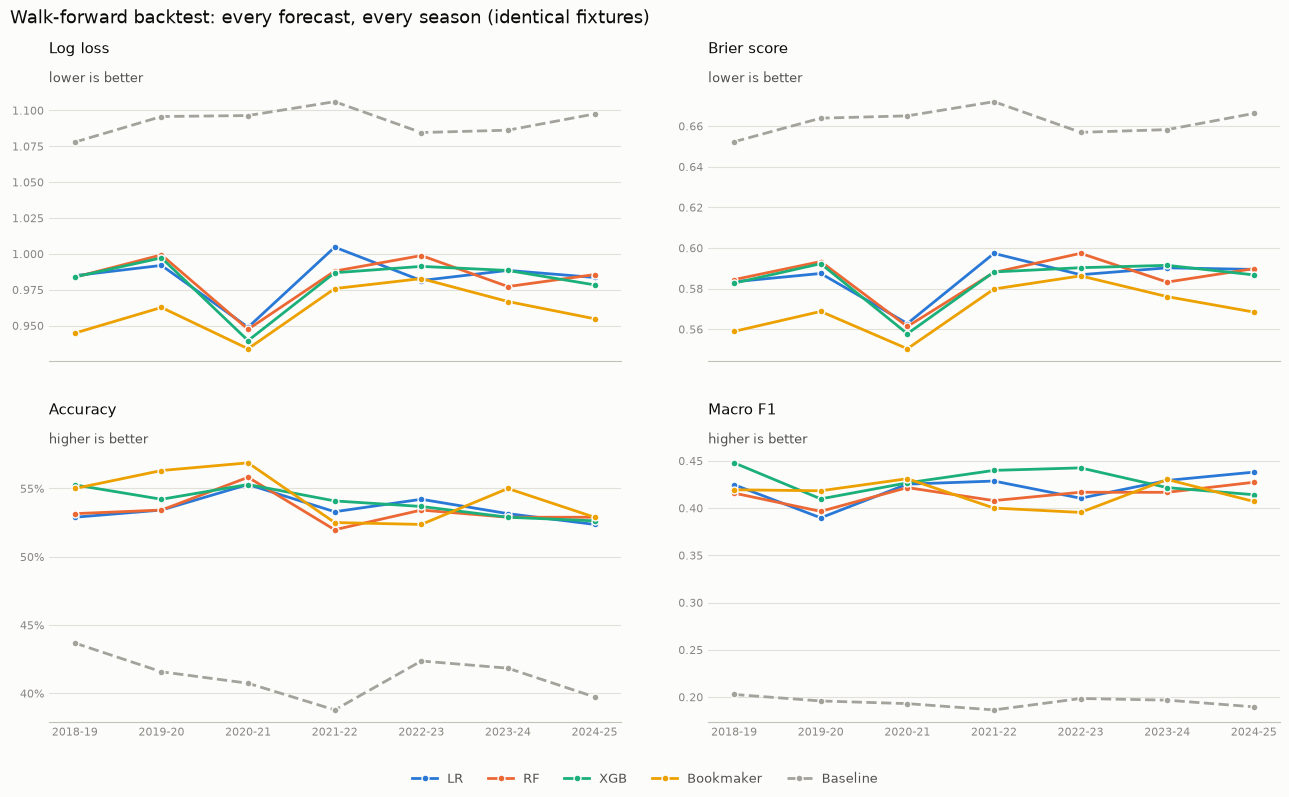

In [6]:
panels = [("log_loss", "Log loss", "lower is better", "{:.2f}"), ("brier", "Brier score", "lower is better", "{:.2f}"),
          ("accuracy", "Accuracy", "higher is better", None), ("macro_f1", "Macro F1", "higher is better", "{:.2f}")]
x = np.arange(len(BACKTEST_SEASONS))
fig, axes = plt.subplots(2, 2, figsize=(13, 8), facecolor=SURFACE, sharex=True)
for ax, (metric, title, note, _) in zip(axes.ravel(), panels):
    wide = seasonal[metric].unstack("forecast")
    for forecast in FORECASTS:
        ax.plot(x, wide[forecast], color=COLORS[forecast], linewidth=2, marker="o", markersize=5,
                linestyle="--" if forecast == BASELINE else "-", label=SHORT[forecast],
                markeredgecolor=SURFACE, markeredgewidth=1)
    if metric == "accuracy":
        ax.yaxis.set_major_locator(MultipleLocator(0.05))
        ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xticks(x, [SEASON_LABELS[s] for s in BACKTEST_SEASONS], fontsize=8.5, color=INK_2)
    style_axes(ax)
    set_title(ax, title, note, size=11)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Walk-forward backtest: every forecast, every season (identical fixtures)",
             x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(h_pad=3, w_pad=4, rect=(0, 0.05, 1, 1))
fig.legend(handles, labels, frameon=False, fontsize=9, labelcolor=INK_2, ncols=5, loc="lower center")
save_figure(fig, "31_backtest_metrics_by_season.png")
plt.show()

**Interpretation**

- **Every season has the same pattern.** The three models sit close together. The bookmaker is
  below them on log loss and Brier score, and the baseline is far above.
  - The models' log loss ranges from 0.940 to 1.005 depending on the season.
  - The baseline's ranges from 1.078 to 1.106.
- **Seasons differ more than models do.** 2020-21 was the most predictable season for all three
  models and for the bookmaker (0.934), while 2019-20, 2021-22 and 2022-23 were among the hardest.
  Each model's log loss moves by about 0.05–0.06 between seasons, more than the gap between the
  models within a season (under 0.02).
- **Accuracy hides most of this.** Over the seven seasons the models get 53–54% right, against
  54.4% for the bookmaker. In 2018-19, 2021-22 and 2022-23, at least one model has *higher*
  accuracy than the bookmaker, yet the bookmaker still has the better log loss in two of those
  three seasons.
- **Macro F1 favours the models**, especially XGBoost (0.430 pooled, against 0.415 for the
  bookmaker). The models predict a few more draws, which macro F1 rewards even though it does not
  improve the probabilities.

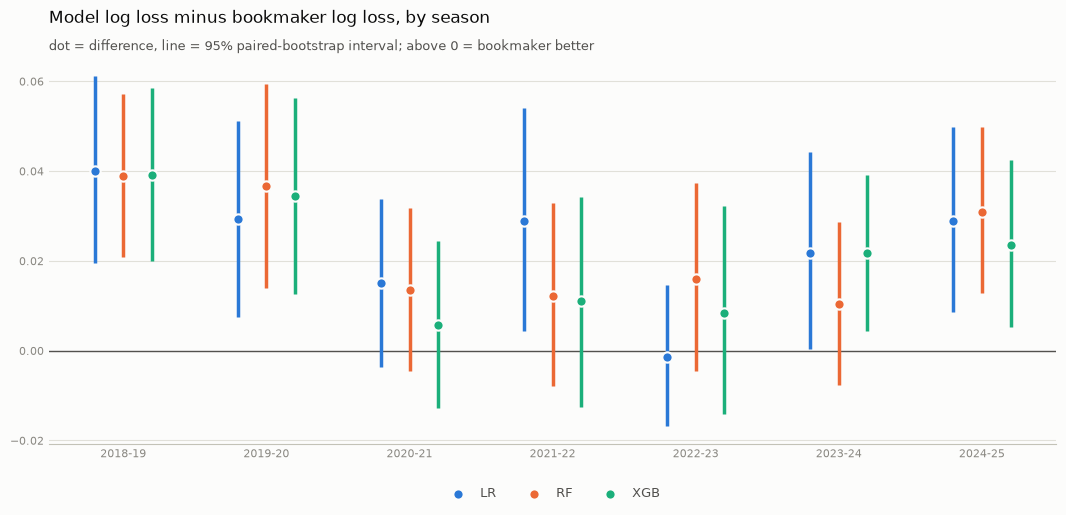

In [7]:
PAIRS = [(m, BOOKMAKER_LABEL) for m in MODELS]
gaps = seasonal_bootstrap(predictions, PAIRS)

fig, ax = plt.subplots(figsize=(13, 5), facecolor=SURFACE)
ax.axhline(0, color=INK_2, linewidth=1, zorder=1)
offsets = {m: o for m, o in zip(MODELS, (-0.2, 0, 0.2))}
for model in MODELS:
    rows = gaps[gaps["a"] == model].set_index("season").loc[list(BACKTEST_SEASONS)]
    xs = x + offsets[model]
    ax.vlines(xs, rows["ci_low"], rows["ci_high"], color=COLORS[model], linewidth=2.5, zorder=2)
    ax.scatter(xs, rows["difference"], s=55, color=COLORS[model], edgecolors=SURFACE, linewidths=1.5, zorder=3,
               label=SHORT[model])
ax.set_xticks(x, [SEASON_LABELS[s] for s in BACKTEST_SEASONS], fontsize=9, color=INK_2)
ax.yaxis.set_major_locator(MultipleLocator(0.02))
style_axes(ax)
ax.legend(frameon=False, fontsize=9, labelcolor=INK_2, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
set_title(ax, "Model log loss minus bookmaker log loss, by season",
          "dot = difference, line = 95% paired-bootstrap interval; above 0 = bookmaker better")
save_figure(fig, "32_backtest_gap_to_bookmaker.png")
plt.show()

gap_table = gaps.assign(a=gaps["a"].map(SHORT), season=gaps["season"].map(SEASON_LABELS)).pivot(
    index="season", columns="a", values=["difference", "ci_low", "ci_high"])
gap_table.style.format("{:+.3f}")

**Interpretation**

- In **every season** except 2022-23, all three models have a higher log loss than the
  bookmaker. The gap ranges from about 0.006 (XGBoost, 2020-21) to 0.040 (2018-19).
- Season by season, the 95% interval excludes zero in 12 of the 21 model-season comparisons, and
  includes it in the other 9. A single season of 380 matches is often not enough to separate a
  model from the bookmaker; that is why the pooled view in section 5 matters.
- **2022-23** is the one season where a model (Logistic Regression, −0.001) scores slightly
  better than the bookmaker. Its interval runs from −0.017 to +0.015, so this is a tie, not a win.

In [8]:
ranks = season_ranks(predictions)[FORECASTS]
ranks.index = ranks.index.map(SEASON_LABELS)
first = (ranks == 1).sum().rename("seasons ranked 1st")
among_models = season_ranks(predictions[predictions["forecast"].isin(MODELS)])[MODELS]
first_models = (among_models == 1).sum().rename("seasons best among the 3 models")
display(ranks.style.set_caption("Rank by log loss within each season (1 = best)"))
pd.concat([first, first_models], axis=1).fillna(0).astype(int)

forecast,Logistic Regression,Random Forest,XGBoost,Bookmaker (Bet365),Baseline
season,,,,,
2018-19,4,2,3,1,5
2019-20,2,4,3,1,5
2020-21,4,3,2,1,5
2021-22,4,3,2,1,5
2022-23,1,4,3,2,5
2023-24,4,2,3,1,5
2024-25,3,4,2,1,5


,seasons ranked 1st,seasons best among the 3 models
forecast,,
Logistic Regression,1,2
Random Forest,0,2
XGBoost,0,3
Bookmaker (Bet365),6,0
Baseline,0,0


**Interpretation**

- The **bookmaker ranks first in 6 of 7 seasons** and the baseline last in all 7.
- **Among the three models there is no consistent winner.** XGBoost is best in 3 seasons, and
  Logistic Regression and Random Forest in 2 each.
- XGBoost is never the worst of the three, which fits its slightly lower pooled log loss
  (section 4). That difference is still within the noise (section 5).

## 4. Averages across seasons: season mean vs pooled

There are two ways to average over seasons:

- **Season mean:** the plain average of the seven seasonal scores. Every season counts once,
  whatever its size.
- **Pooled:** all per-match predictions from every season are put together and scored once.
  Every *match* counts once.

For log loss and Brier score, the pooled value is the match-weighted mean of the seasonal values.
For accuracy and especially macro F1, the pooled value has to be computed from the pooled
predictions, because F1 is not an average over matches. Here every season has 378–380 scored
fixtures, so the two methods agree closely; they would drift apart if seasons differed in size
or coverage.

In [9]:
summary = summary_table(predictions)
cols = ["seasons", "matches"] + [f"{m}_{a}" for m in METRICS for a in ("season_mean", "pooled")] + \
       ["log_loss_best_season", "log_loss_worst_season"]
summary = summary[cols]
summary.style.format({c: ("{:.1%}" if c.startswith("accuracy") else "{:.4f}") for c in cols[2:]} |
                     {"matches": "{:,}"})

,seasons,matches,accuracy_season_mean,accuracy_pooled,macro_f1_season_mean,macro_f1_pooled,log_loss_season_mean,log_loss_pooled,brier_season_mean,brier_pooled,log_loss_best_season,log_loss_worst_season
Logistic Regression,7,"2,657",53.5%,53.5%,0.4209,0.4223,0.9834,0.9834,0.5853,0.5854,0.9488,1.0047
Random Forest,7,"2,657",53.4%,53.4%,0.4147,0.4153,0.9829,0.9829,0.5853,0.5854,0.9474,0.9993
XGBoost,7,"2,657",54.0%,54.0%,0.4289,0.4297,0.9808,0.9808,0.5842,0.5842,0.9395,0.9972
Bookmaker (Bet365),7,"2,657",54.4%,54.4%,0.4145,0.4147,0.9602,0.9602,0.5698,0.5698,0.9339,0.9828
Baseline,7,"2,657",41.2%,41.2%,0.1946,0.1947,1.0921,1.0921,0.6621,0.6621,1.0779,1.1061


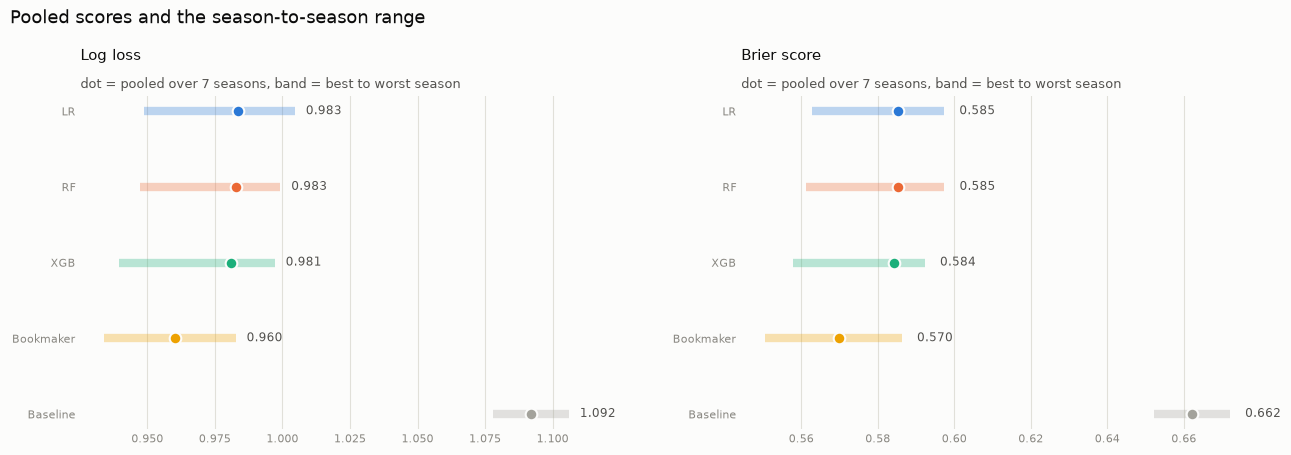

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), facecolor=SURFACE)
for ax, metric, title in ((axes[0], "log_loss", "Log loss"), (axes[1], "brier", "Brier score")):
    wide = seasonal[metric].unstack("forecast")
    y = np.arange(len(FORECASTS))[::-1]
    for yi, forecast in zip(y, FORECASTS):
        lo, hi = wide[forecast].min(), wide[forecast].max()
        ax.hlines(yi, lo, hi, color=COLORS[forecast], linewidth=6, alpha=0.3, zorder=1)
        pooled_value = summary.loc[forecast, f"{metric}_pooled"]
        ax.scatter(pooled_value, yi, s=70, color=COLORS[forecast], edgecolors=SURFACE, linewidths=1.5, zorder=3)
        ax.text(hi + 0.004, yi, f"{pooled_value:.3f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_yticks(y, [SHORT[f] for f in FORECASTS], fontsize=9, color=INK_2)
    style_axes(ax, grid="x")
    ax.spines["bottom"].set_visible(False)
    set_title(ax, title, "dot = pooled over 7 seasons, band = best to worst season", size=11)
fig.suptitle("Pooled scores and the season-to-season range", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(w_pad=4)
save_figure(fig, "33_backtest_pooled_summary.png")
plt.show()

**Interpretation**

- **Pooled log loss over 2,657 matches:**
  - XGBoost 0.981, Random Forest 0.983, Logistic Regression 0.983
  - Bookmaker 0.960
  - Baseline 1.092
- Each model removes about 0.11 log loss compared with the baseline, and remains about 0.02
  behind the bookmaker.
- **The season mean and the pooled value agree to four decimals for log loss and Brier score.**
  Every season has 378–380 scored matches, so match-weighting barely changes anything.
- **Macro F1 differs slightly** (e.g. Logistic Regression 0.421 as a season mean against 0.422
  pooled), because F1 computed on pooled predictions is not the average of seasonal F1 scores.
- The bands show that each model's season-to-season range (about 0.05–0.06 log loss) is wider
  than the gaps between the models and the bookmaker. That is why one season, like 2025-26 in commits 7–8, is a
  weak basis for ranking models.

## 5. Pooled uncertainty

The same paired bootstrap as notebook 05, now over all pooled matches from the seven seasons.
Each comparison takes two forecasts' log loss on the same matches; a negative difference means
the first forecast is better.

In [11]:
POOLED_PAIRS = [(m, BOOKMAKER_LABEL) for m in MODELS] + [(m, BASELINE) for m in MODELS] + [
    ("Logistic Regression", "Random Forest"), ("Logistic Regression", "XGBoost"), ("Random Forest", "XGBoost")]
pooled_boot = pooled_bootstrap(predictions, POOLED_PAIRS)
pooled_boot.assign(a=pooled_boot["a"].map(SHORT), b=pooled_boot["b"].map(SHORT)).drop(columns="metric").style.format(
    {"difference": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "share_a_better": "{:.0%}"})

,a,b,matches,difference,ci_low,ci_high,share_a_better,ci_includes_zero
0,LR,Bookmaker,2657,+0.0232,+0.0154,+0.0312,0%,False
1,RF,Bookmaker,2657,+0.0227,+0.0153,+0.0301,0%,False
2,XGB,Bookmaker,2657,+0.0206,+0.0130,+0.0284,0%,False
3,LR,Baseline,2657,-0.1086,-0.1262,-0.0909,100%,False
4,RF,Baseline,2657,-0.1092,-0.1247,-0.0930,100%,False
5,XGB,Baseline,2657,-0.1112,-0.1279,-0.0938,100%,False
6,LR,RF,2657,+0.0005,-0.0055,+0.0067,44%,True
7,LR,XGB,2657,+0.0026,-0.0027,+0.0079,18%,True
8,RF,XGB,2657,+0.0021,-0.0026,+0.0067,19%,True


**Interpretation**

- **Models vs bookmaker:** pooled over seven seasons, each model's log loss is 0.021–0.023 higher.
  - The 95% intervals (roughly +0.013 to +0.031) exclude zero for all three models.
  - The Brier score gives the same picture.
  - Together with the bookmaker ranking first in 6 of 7 seasons, this is consistent evidence that
    the bookmaker's probabilities are better than the models', by a small but persistent margin.
- **Models vs baseline:** every model is better by about 0.11, with intervals far from zero.
- **Between the models:** the differences are at most 0.003, and every interval includes zero.
  Even with 2,657 matches, Logistic Regression, Random Forest and XGBoost cannot be told apart.
- **Caveats:**
  - The bootstrap treats matches as independent. Matches in the same round or season share
    conditions, so the true uncertainty is somewhat larger.
  - Nine comparisons are made without a multiple-comparison correction.
  - The tuning grids were designed in commit 7 (see the method note above).

  None of these caveats changes the direction of the findings: the gap to the bookmaker is between
  two and three times its interval's half-width.

## 6. Context: the commit-7 results on 2025-26 and 2026-27

These numbers are **not recomputed here**. They are read from `outputs/models/model_comparison.csv`
for comparison only. They come from the commit-7 settings, which were tuned on 2025-26, so the
2025-26 values are slightly optimistic, while 2026-27 is a partial season of 100 matches.

In [12]:
path = MODELS_DIR / "model_comparison.csv"
if path.exists():
    commit7 = pd.read_csv(path).set_index(["split", "model"])["log_loss"].unstack("split")
    commit7 = commit7.rename(index={"Baseline (always most frequent)": BASELINE})
    context = pd.DataFrame({
        "backtest pooled 2018-19 to 2024-25": summary["log_loss_pooled"],
        "backtest worst season": summary["log_loss_worst_season"],
        "commit 7: validation 2025-26": commit7.get("validation"),
        "commit 7: test 2026-27 (100 matches)": commit7.get("test"),
    }).loc[[f for f in FORECASTS if f != BOOKMAKER_LABEL]]
    display(context.style.format("{:.3f}", na_rep="-").set_caption("Log loss"))
else:
    print("outputs/models/model_comparison.csv not found; run python -m src.train to create it.")

,backtest pooled 2018-19 to 2024-25,backtest worst season,commit 7: validation 2025-26,commit 7: test 2026-27 (100 matches)
Logistic Regression,0.983,1.005,1.002,0.882
Random Forest,0.983,0.999,1.003,0.895
XGBoost,0.981,0.997,1.005,0.882
Baseline,1.092,1.106,1.102,1.060


**Interpretation**

- **2025-26 was a hard season for every forecast.**
  - The models scored 1.002–1.005 on 2025-26 in commit 7, worse than their pooled backtest
    (0.981–0.983) and at or beyond the worst season in the backtest (0.997–1.005).
  - The bookmaker's 0.982 on 2025-26 is also at the worst end of its backtest range
    (0.934–0.983).
  - So the poor 2025-26 scores reflect a hard season, not a sign that the commit-7 models are
    worse. (The comparison is approximate: the commit-7 settings were chosen differently from
    the backtest folds' settings.)
- **The gap to the bookmaker matches.** The commit-7 models trailed the bookmaker by 0.020–0.023
  on 2025-26, the same size as the pooled backtest gap. Notebook 05's validation result is
  typical, not a one-off.
- **The 2026-27 test scores (about 0.88) are far better than any backtest season.** They come
  from only 100 early-season matches with an unusually high share of home wins and few draws.
  Expect them to rise towards the backtest range as the season goes on.

## Key findings

| Finding | Detail |
|---|---|
| The models are consistently useful | About 0.11 log loss better than the baseline in every season; 53–54% accuracy against 41% |
| The bookmaker is consistently better | First in 6 of 7 seasons; pooled gap of 0.021–0.023 log loss, with 95% intervals excluding 0 for all three models |
| No model beats another | Each model is best among the three in 2–3 seasons; pooled differences ≤ 0.003, all intervals include 0 |
| Seasons vary more than models | Each model's log loss moves by about 0.05–0.06 across seasons, more than the gaps between the models |
| 2025-26 was a hard season | Commit-7 validation scores are at the worst end of the backtest range for models *and* bookmaker; the gap to the bookmaker is typical |
| Accuracy and macro F1 can mislead | Models sometimes match or beat the bookmaker on accuracy or macro F1 while losing on log loss |
| Selected settings are unstable, results are not | Hyperparameters and feature sets change between folds, but scores barely move: the tuning landscape is flat |

**What this means for the project:** with these features, the choice of algorithm hardly matters.
The persistent 0.02 gap to the bookmaker comes from information the models do not have (team
news, transfers, market information), so future gains need better features, not different models.

## Limitations

- Seven seasons (2018-19 to 2024-25) and one bookmaker. Earlier seasons are possible, but the
  bookmaker margin was much higher before 2014-15, which would complicate the comparison.
- Tuning uses a single inner validation season, so the selected settings are noisy (section 1).
- The grid ranges were set in commit 7 after seeing 2025-26 results.
- The bootstrap assumes independent matches and uses no multiple-comparison correction.

## Next steps

- **Commit 11:** final documentation and presentation. This framework can then be reused to test
  improvements (recency weighting, Elo ratings, new features) on seven seasons instead of one.